In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Load raw dataset from OneDrive
file_path = r"C:\Users\Admin\OneDrive\bank_churn_dirty.csv"
df = pd.read_csv(file_path)
print("Raw dataset shape:", df.shape)

Raw dataset shape: (8715, 18)


In [3]:
# Drop rows missing a primary customer ID
df.dropna(subset=["customer_id"], inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_12028\1590673861.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["customer_id"], inplace=True)


In [4]:
df.fillna({
    "email": "unknown@noemail.com",
    "estimated_salary": df["estimated_salary"].median()
}, inplace=True)


,customer_id,nome,email,numero_conta,data_nascimento,cidade,country,gender,age,credit_score,tenure,balance,limite_credito,products_number,credit_card,active_member,estimated_salary,churn
0,15631460.0,Camila Martins Lima,camila.martins@hotmail.com,83406-0,04/10/1982,Barcelona,Spain,Female,42,671,3,0.00,0.00,2,1,1,128449.33,0
1,15700300.0,Patrícia Rocha Alves,patricia.rocha@uol.com.br,83680-0,18/12/1980,Berlin,Germany,Female,44,674,4,131593.85,202324.81,1,0,1,171345.02,1
2,15760456.0,Silvana Costa Ferreira,silvana.costa@outlook.com,43299-9,1986-04-04,Paris,France,Female,38,731,10,123711.73,262028.34,2,1,0,171340.68,1
3,15772482.0,André Costa Araújo,andre.costa@gmail.com,19234-4,1996-03-07,Munich,Germany,Male,28,829,3,132405.52,366908.12,3,1,0,104889.20,1
4,15782236.0,Carlos Eduardo Silva,carlos.eduardo@uol.com.br,52424-4,20/08/1990,Madrid,Spain,Male,34,735,5,0.00,0.00,2,0,0,71095.41,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8710,15599410.0,Rodrigo Santos Gomes,rodrigo.santos@yahoo.com.br,25328-2,10/03/1983,Nantes,France,Male,41,721,2,0.00,0.00,2,1,0,168219.75,0
8711,15812518.0,Silvana Costa Ferreira,silvana.costa@yahoo.com.br,00562-4,28/06/1987,Sevilla,Spain,Female,37,657,0,163607.18,84062.24,1,0,1,44203.55,0
8712,15609676.0,Natália Santos Martins,natalia.santos@gmail.com,33095-9,1989-01-13,Toulouse,France,Female,35,718,2,167924.95,370498.05,1,1,0,43024.64,0
8713,15665521.0,Lucas Ferreira Lima,lucas.ferreira@outlook.com,33170-1,2006-10-11,Berlin,Germany,Male,18,642,5,111183.53,303204.19,2,0,1,10063.75,0


In [6]:
# Remove exact full-row duplicates and duplicate unique identifiers
df.drop_duplicates(inplace=True)
df.drop_duplicates(subset=["customer_id"], keep="first", inplace=True)
df.drop_duplicates(subset=["numero_conta"], keep="first", inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_12028\3867578823.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_12028\3867578823.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset=["customer_id"], keep="first", inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_12028\3867578823.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_

In [9]:
# Enforce real-world banking number rules
df = df[(df["age"] >= 18) & (df["age"] <= 100)]
df = df[(df["balance"] >= 0) & (df["balance"] != 999999)]
df = df[(df["credit_score"] >= 300) & (df["credit_score"] <= 850)]

In [10]:
# Standardize text categories using a loop
for col in ["cidade", "country", "gender"]:
    df[col] = df[col].str.strip().str.title()


In [11]:
# Parse mixed DD/MM/YYYY and YYYY-MM-DD birth dates into uniform calendar dates
df["data_nascimento"] = pd.to_datetime(
    df["data_nascimento"], format="mixed", dayfirst=True, errors="coerce"
)
df.dropna(subset=["data_nascimento"], inplace=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_12028\3705745391.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["data_nascimento"], inplace=True)


In [13]:
# Polish ID data type, reset row index, and export clean CSV
df["customer_id"] = df["customer_id"].astype("int64")
df.reset_index(drop=True, inplace=True)
df.to_csv("bank_churn_clean.csv", index=False)
print("Clean dataset shape:", df.shape)
print("Remaining nulls:", df.isna().sum().sum())

Clean dataset shape: (8715, 18)
Remaining nulls: 0


C:\Users\Admin\AppData\Local\Temp\ipykernel_12028\459914310.py:3: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)


In [15]:
# Headline churn rate and lost deposits
churn_rate = df["churn"].mean() * 100
lost_deposits = df[df["churn"] == 1]["balance"].sum()
total_deposits = df["balance"].sum()

print(f"Overall Churn Rate: {churn_rate:.2f}%")
print(f"Total Deposits Lost: ${lost_deposits:,.2f} (out of ${total_deposits:,.2f})")

Overall Churn Rate: 20.22%
Total Deposits Lost: $157,907,797.75 (out of $654,250,047.65)


In [16]:
# Compare averages between Retained (0) and Churned (1)
print("\n--- STAYED (0) vs. LEFT (1) AVERAGES ---")
print(df.groupby("churn")[["age", "balance", "credit_score", "estimated_salary"]].mean().round(2))


--- STAYED (0) vs. LEFT (1) AVERAGES ---
         age   balance  credit_score  estimated_salary
churn                                                 
0      37.30  71385.34        651.54         100054.15
1      44.89  89618.50        644.85         101469.94


In [18]:
# Churn rate across key banking segments
for col in ["country", "products_number", "active_member", "gender"]:
    print(f"\n--- CHURN RATE BY {col.upper()} ---")
    print(df.groupby(col)["churn"].agg(
        total_customers="count",
        churn_rate_pct=lambda x: round(x.mean() * 100, 2)
    ))



--- CHURN RATE BY COUNTRY ---
         total_customers  churn_rate_pct
country                                 
France              4394           16.20
Germany             2141           32.32
Spain               2180           16.42

--- CHURN RATE BY PRODUCTS_NUMBER ---
                 total_customers  churn_rate_pct
products_number                                 
1                           4403           27.75
2                           4023            7.26
3                            236           82.63
4                             53          100.00

--- CHURN RATE BY ACTIVE_MEMBER ---
               total_customers  churn_rate_pct
active_member                                 
0                         4261           26.73
1                         4454           13.99

--- CHURN RATE BY GENDER ---
        total_customers  churn_rate_pct
gender                                 
Female             3981           24.97
Male               4734           16.22


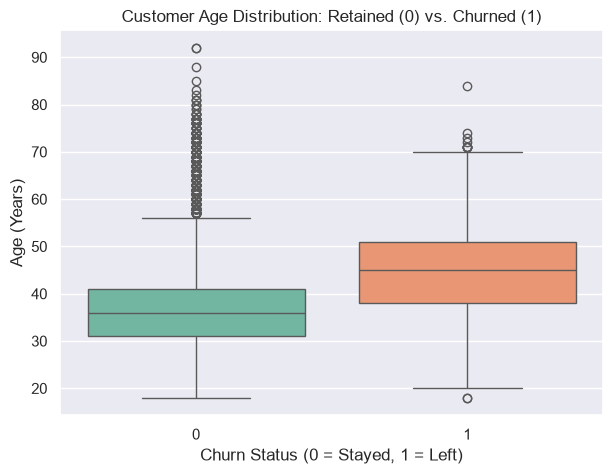

In [31]:

# Set a clean visual theme
sns.set_theme()

# Single chart example: Compare age spread between Stayed (0) and Churned (1)
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="churn", y="age", hue="churn", palette="Set2", legend=False)
plt.title("Customer Age Distribution: Retained (0) vs. Churned (1)")
plt.xlabel("Churn Status (0 = Stayed, 1 = Left)")
plt.ylabel("Age (Years)")
plt.show()